In [17]:
import warnings

# Ignore FutureWarnings and warnings related to inplace operations
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*inplace.*")

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from data_collection import collect_stock_data, tickers_earnings_long, tickers_historical_sd

Calculates the number of trading days required for multiple stock tickers'
price to settle within its firm-specific historical volatility band for N
consecutive trading days following each quarterly earnings announcement, for each year.

**Algorithm:**
1. Beginning the day after each earnings announcement, track
   daily price returns.
2. A price is considered "stable" when its absolute daily
   return falls within ± one firm-specific historical standard
   deviation (σ) for N consecutive trading days.
3. Settlement time = total days elapsed − N confirmation days

**Key Parameters:**
- tickers: array of tickers
- year: integer value of the year of investigation
- N: minimum consecutive days within band required to confirm
  equilibrium (e.g. N = 3)

**Output:** Single integer per earnings event representing
the number of trading days to price discovery completion

In [ ]:
def price_discovery_completion_metric(
        tickers: list[str],
        year: int,
        interval: str,
        N: int,
        max_window: int = 60
    ) -> pd.DataFrame:
    """
    Calculates the number of trading days from the earnings reaction day
    (day 0) to the trigger day of the first settlement: a day whose
    |return| <= historical SD, followed by N consecutive days whose
    High/Low stay inside trigger close +/- historical SD.

    Returns:
        pd.DataFrame with columns: Ticker, Quarter, Earnings Date,
        Settlement Days (None if no settlement within max_window days)
    """
    tickers_data = collect_stock_data(tickers, year, interval)
    earnings_dates = tickers_earnings_long(tickers, year)
    historical_sd_df = tickers_historical_sd(tickers, earnings_dates, interval)

    results = []
    for ticker in tickers:
        ticker_data = tickers_data[
            tickers_data.index.get_level_values('Ticker') == ticker
        ].sort_index()
        historical_sd_per_ticker = historical_sd_df[historical_sd_df['Ticker'] == ticker]

        # Per-ticker arrays, computed once (returns on full history so
        # the reaction day has a prior close)
        close = ticker_data['Close']
        ret_arr = close.pct_change().abs().to_numpy()
        high_arr = ticker_data['High'].to_numpy()
        low_arr = ticker_data['Low'].to_numpy()
        close_arr = close.to_numpy()
        dates = ticker_data.index.get_level_values('Date')

        for quarter in range(1, 5):
            historical_sd_row = historical_sd_per_ticker[
                historical_sd_per_ticker['Quarter'] == quarter
            ]

            if historical_sd_row.empty:
                print(f"* No historical SD for {ticker} Q{quarter}")
                continue

            # Gets historical SD per stock's quarter
            historical_sd = historical_sd_row['Historical SD'].iloc[0]
            historical_sd = historical_sd.iloc[0]

            announcement_date = historical_sd_row['Earnings Date'].iloc[0]
            # Removes timezone info if present
            if announcement_date.tzinfo:
                announcement_date = announcement_date.tz_localize(None)

            # After-close announcements react on the next trading day
            if announcement_date.hour >= 16:
                start_day = announcement_date.normalize() + pd.Timedelta(days=1)
            else:
                start_day = announcement_date.normalize()

            start_pos = dates.searchsorted(start_day)  # first trading day on/after start_day
            if start_pos >= len(close_arr):
                print(f"* No post-announcement data for {ticker} Q{quarter}")
                continue
            # Max window for calculation is 2 months (60 trading days)
            end_pos = min(start_pos + max_window, len(close_arr))

            settlement_day = None
            trigger_pos = None
            count = 0
            upper = lower = None

            for pos in range(start_pos, end_pos):
                if np.isnan(ret_arr[pos]):
                    continue

                if trigger_pos is not None:
                    if low_arr[pos] > lower and high_arr[pos] < upper:
                        count += 1
                        if count >= N:
                            settlement_day = trigger_pos - start_pos  # 0 = reaction day
                            break
                        continue
                    # Band broken: reset, then fall through so today can start a new trigger
                    trigger_pos = None
                    count = 0

                if ret_arr[pos] <= historical_sd:
                    trigger_pos = pos
                    upper = close_arr[pos] * (1 + historical_sd)
                    lower = close_arr[pos] * (1 - historical_sd)

            if settlement_day is None:
                print(f"Never settled within {max_window} days for {ticker} Q{quarter}")

            results.append({
                'Ticker': ticker,
                'Quarter': quarter,
                'Earnings Date': announcement_date,
                'Settlement Days': settlement_day
            })

    return pd.DataFrame(results)

Testing **price_discovery_completion_metric()** Function

In [19]:
tickers = ['META', 'NVDA', 'AAPL', 'MSFT']
year = 2013
N = 2
interval = '1d'
df = price_discovery_completion_metric(tickers, year, interval, N)
print(df)

   Ticker  Quarter       Earnings Date  Settlement Days
0    META        1 2013-01-30 16:00:00                3
1    META        2 2013-05-01 16:00:00                3
2    META        3 2013-07-24 16:00:00                8
3    META        4 2013-10-30 16:00:00               13
4    NVDA        1 2013-02-13 16:00:00                3
5    NVDA        2 2013-05-09 16:00:00                3
6    NVDA        3 2013-08-08 16:00:00                6
7    NVDA        4 2013-11-07 16:00:00                9
8    AAPL        1 2013-01-23 16:00:00                3
9    AAPL        2 2013-04-23 16:00:00                9
10   AAPL        3 2013-07-23 16:00:00                4
11   AAPL        4 2013-10-28 16:00:00                1
12   MSFT        1 2013-01-24 16:00:00                0
13   MSFT        2 2013-04-18 16:00:00               10
14   MSFT        3 2013-07-18 16:00:00                7
15   MSFT        4 2013-10-24 16:00:00                1


Loop through each year (key) and it's tickers (values) to get a DataFrame of each year's tickers' days to settlement (price disovery completion metric)

**Algorithm:**
1. Accesses dictionary values--- year (key) and tickers (value)--- to collect necessary tickers' data (e.g. earnings)
2. Runs through the price_discovery_completion metric() function, creating a table for each year's TICKERS
3. Appends the each yearly table's results into one DataFrame

**Key Parameters:**
1. yearly_tickers: dictionary of stock values with their respective years
2. interval: time frame the stock OHLCV is taken (e.g. '1h', "1d", '5d', '1wk', '1mo')
3. N: number of consecutive days until settlement completion is met

**Output:** Dataframe that includes every year's stock time of settlement given the N consecutive days parameter (row: stock ticker; column: Quarter, Earnings Date, Time Till Settlement Days)

In [20]:
def yearly_ticker_evaluation(
        yearly_ticker: dict[str],
        interval: str,
        N: int
        ) -> pd.DataFrame:
    all_result = []

    for year, tickers in yearly_ticker.items():
        year_int = int(year)
        yearly_price_metric = price_discovery_completion_metric(tickers, year_int, interval, N)

        if yearly_price_metric is None or yearly_price_metric.empty:
            print(f"* No results for year {year_int}")
            continue

        yearly_price_metric = yearly_price_metric.copy()
        yearly_price_metric['Year'] = year_int
        all_result.append(yearly_price_metric)

    if not all_result:
        return pd.DataFrame()

    return pd.concat(all_result, ignore_index=True)

Testing **yearly_ticker_evaluation()** Function

In [21]:
yearly_tickers = {
    '2020': ['META', 'AAPL'],
    '2019': ['META', 'AAPL'],
    '2010': ['NVDA', 'WMT']
    }
interval = '1d'
N = 1
df = yearly_ticker_evaluation(yearly_tickers, interval, N)
print(df)

   Ticker  Quarter       Earnings Date  Settlement Days  Year
0    META        1 2020-01-29 16:00:00                4  2020
1    META        2 2020-04-29 17:00:00                1  2020
2    META        3 2020-07-30 16:00:00                1  2020
3    META        4 2020-10-29 16:00:00                4  2020
4    AAPL        1 2020-01-28 16:00:00                5  2020
5    AAPL        2 2020-04-30 17:00:00                0  2020
6    AAPL        3 2020-07-30 16:00:00                1  2020
7    AAPL        4 2020-10-29 16:00:00                1  2020
8    META        1 2019-01-30 16:00:00                1  2019
9    META        2 2019-04-24 16:00:00                1  2019
10   META        3 2019-07-24 16:00:00                0  2019
11   META        4 2019-10-30 16:00:00                0  2019
12   AAPL        1 2019-01-29 16:00:00                1  2019
13   AAPL        2 2019-04-30 16:00:00                1  2019
14   AAPL        3 2019-07-30 16:00:00                4  2019
15   AAP

Plots **Boxplot** for each stock's yearly settlement data.

In [22]:
def boxplot_yearly_settlement_period(
    df: pd.DataFrame
    ) -> None:
    """
    df: Dataframe that contains the settlement period data for each yearly tickers
    """

    df.boxplot(column='Settlement Days', by='Year', grid=False)
    plt.title('Settlement Periods by Year')
    plt.suptitle('')
    plt.xlabel('Year')
    plt.ylabel('Settlement Days')
    plt.show()

Testing **boxplot_yearly_settlement_period()** Function

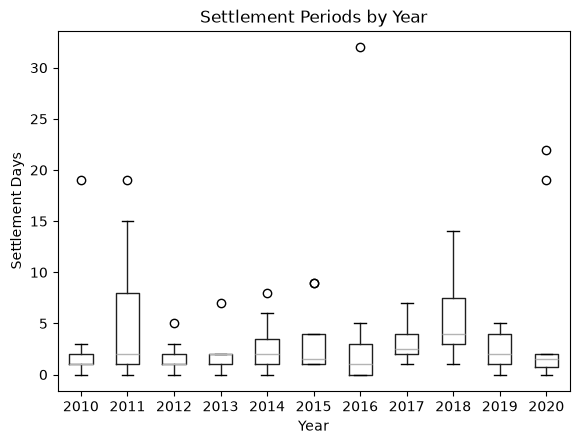

In [23]:
# Example scenario
yearly_tickers = {
    '2010': ['KO', 'INTC', 'CAT'],
    '2011': ['JNJ', 'ORCL', 'HD'],
    '2012': ['AAPL', 'PFE', 'MCD'],
    '2013': ['XOM', 'NKE', 'CSCO'],
    '2014': ['MSFT', 'WMT', 'BA'],
    '2015': ['PG', 'AMZN', 'MMM'],
    '2016': ['JPM', 'DIS', 'IBM'],
    '2017': ['NVDA', 'CVX', 'UNH'],
    '2018': ['T', 'MRK', 'GOOGL'],
    '2019': ['VZ', 'AMD', 'GE'],
    '2020': ['COST', 'LMT', 'ADBE'],
}
interval = '1d'
N = 1
df = yearly_ticker_evaluation(yearly_tickers, interval, N)
boxplot_yearly_settlement_period(df)

Plots **Histogram Frequency Graph** ranging from Min and Max Settlement Days

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_histogram_graph(
    df: pd.DataFrame,
    start: int,
    end: int
    ) -> None:
    """
    df: DataFrame with a 'Settlement Days' column (one row per earnings event)
    start: First year, used in the title
    end: Last year, used in the title

    Output: Bar graph of how often each settlement period occurred.
    """
    # Drops empty data points
    days = df['Settlement Days'].dropna().astype(int)
    if days.empty:
        print("No settlement data to plot.")
        return

    counts = days.value_counts().reindex(range(0, days.max() + 1), fill_value=0)

    fig_width = max(8, len(counts) * 0.5)   # 0.5 inch per day, minimum 8
    fig, ax = plt.subplots(figsize=(fig_width, 6))

    ax.bar(counts.index, counts.values, width=0.8, edgecolor='black')

    ax.set_title(f'Frequency of Settlement Periods ({start}-{end})')
    ax.set_xlabel('Settlement Days')
    ax.set_ylabel('Frequency')
    ax.set_xticks(counts.index)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_axisbelow(True)   # gridlines behind the bars
    plt.xlim(-0.5, len(counts) - 0.5)  # Adjust x-axis limits to fit bars

    plt.show()

    median = days.median()
    mean = days.mean()
    print(f"Median Settlement Days: {median}")
    print(f"Mean Settlement Days: {mean}")

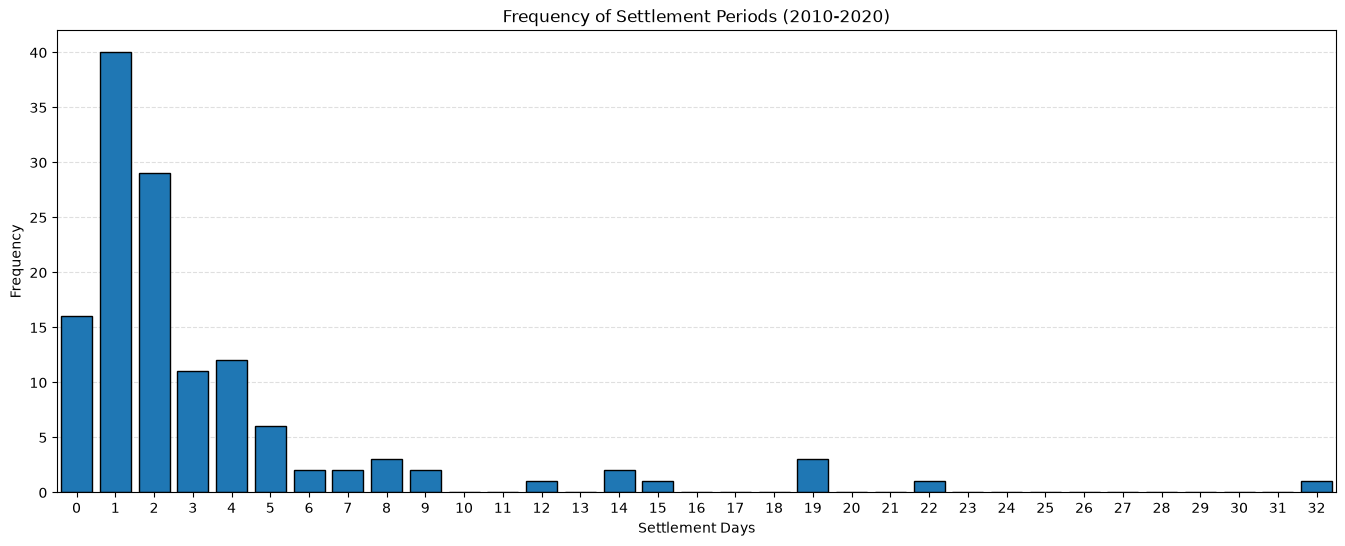

Median Settlement Days: 2.0
Mean Settlement Days: 3.356060606060606


In [25]:
# Example scenario
yearly_tickers = {
    '2010': ['KO', 'INTC', 'CAT'],
    '2011': ['JNJ', 'ORCL', 'HD'],
    '2012': ['AAPL', 'PFE', 'MCD'],
    '2013': ['XOM', 'NKE', 'CSCO'],
    '2014': ['MSFT', 'WMT', 'BA'],
    '2015': ['PG', 'AMZN', 'MMM'],
    '2016': ['JPM', 'DIS', 'IBM'],
    '2017': ['NVDA', 'CVX', 'UNH'],
    '2018': ['T', 'MRK', 'GOOGL'],
    '2019': ['VZ', 'AMD', 'GE'],
    '2020': ['COST', 'LMT', 'ADBE'],
}
interval = '1d'
N = 1
df = yearly_ticker_evaluation(yearly_tickers, interval, N)

year = list(yearly_tickers.keys())
start = year[0]
end = year[-1]

plot_histogram_graph(df, start, end)